# 03 - Modelo 1: BENIGN x Ataque

Primeira etapa do IDS. Todo fluxo passa por este modelo; os classificados como ataque seguem para o
modelo de tipo (notebook 04).

A metrica mais importante aqui e o **recall da classe Ataque**: um ataque que passa por este modelo
nunca chega ao segundo. Por isso o limiar de decisao e escolhido para favorecer o recall (F2),
usando so o treino (validacao cruzada).

## 1. Setup

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

from src.data import build_dataset, train_test, split_xy
from src.features import make_model, shap_importance, stratified_sample, XGB_PARAMS
from src.pipeline import MODELS_DIR, save_model

PARAMS = dict(n_estimators=300)

## 2. Dados e features

In [2]:
with open(MODELS_DIR / 'selecao_features_binario.json', encoding='utf-8') as f:
    features = json.load(f)['features']

df = build_dataset()
train, test = train_test(df)
X_train, y_train, _ = split_xy(train)
X_test, y_test, _ = split_xy(test)
X_train, X_test = X_train[features], X_test[features]

print(f'{len(features)} features')
print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Proporcao de ataques no treino:', round(y_train.mean(), 3))

20 features
Treino: (362820, 20) | Teste: (90705, 20)
Proporcao de ataques no treino: 0.291


## 3. Escolha do limiar

Probabilidades *out-of-fold* (validacao cruzada com 5 folds no treino): cada fluxo recebe a previsao
de um modelo que nao o viu no treino. O limiar escolhido maximiza o **F2**, que pesa o recall
duas vezes mais que a precisao.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = np.zeros(len(y_train))
for tr, va in skf.split(X_train, y_train):
    modelo = make_model(2, **PARAMS)
    modelo.fit(X_train.iloc[tr], y_train.iloc[tr])
    oof[va] = modelo.predict_proba(X_train.iloc[va])[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof)
f2 = 5 * precision * recall / (4 * precision + recall + 1e-12)
best = np.argmax(f2[:-1])
threshold = float(thresholds[best])
print(f'Limiar escolhido: {threshold:.4f}')

Limiar escolhido: 0.1622


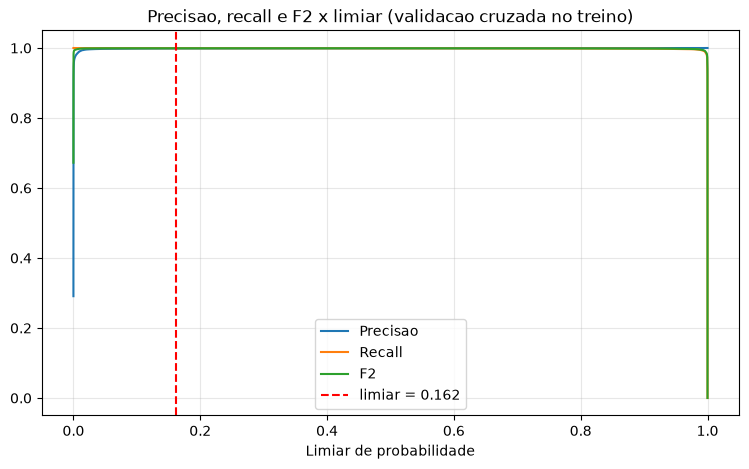

,limiar,falsos negativos (ataques perdidos),falsos positivos (alarmes falsos)
0,0.1000,57,194
1,0.3000,78,111
2,0.5000,101,69
3,0.7000,122,43
4,0.1622,63,151


In [4]:
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precision[:-1], label='Precisao')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.plot(thresholds, f2[:-1], label='F2')
plt.axvline(threshold, color='red', linestyle='--', label=f'limiar = {threshold:.3f}')
plt.xlabel('Limiar de probabilidade')
plt.title('Precisao, recall e F2 x limiar (validacao cruzada no treino)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


def resumo_limiar(y, prob, t):
    pred = prob >= t
    return {'limiar': round(t, 4),
            'falsos negativos (ataques perdidos)': int(((y == 1) & ~pred).sum()),
            'falsos positivos (alarmes falsos)': int(((y == 0) & pred).sum())}


pd.DataFrame([resumo_limiar(y_train, oof, t) for t in [0.1, 0.3, 0.5, 0.7, threshold]])

## 4. Treino final e avaliacao no teste

In [5]:
modelo = make_model(2, **PARAMS)
modelo.fit(X_train, y_train)

prob_test = modelo.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= threshold).astype(int)

print(classification_report(y_test, pred_test, target_names=['BENIGN', 'Ataque'], digits=4))

              precision    recall  f1-score   support

      BENIGN     0.9997    0.9995    0.9996     64321
      Ataque     0.9989    0.9994    0.9991     26384

    accuracy                         0.9995     90705
   macro avg     0.9993    0.9994    0.9994     90705
weighted avg     0.9995    0.9995    0.9995     90705



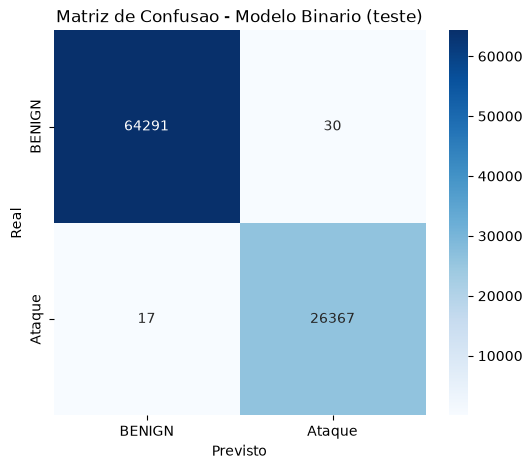

In [6]:
cm = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['BENIGN', 'Ataque'], yticklabels=['BENIGN', 'Ataque'])
plt.title('Matriz de Confusao - Modelo Binario (teste)')
plt.ylabel('Real')
plt.xlabel('Previsto')
plt.show()

### 4.1 Recall por tipo de ataque

Quais ataques passam despercebidos pelo primeiro modelo.

In [7]:
recall_tipo = (test.assign(detectado=pred_test)
               .query('is_attack == 1')
               .groupby('attack_type')['detectado']
               .agg(recall='mean', fluxos='size'))
recall_tipo

,recall,fluxos
attack_type,,
DDoS,0.999570,25598
PortScan,0.994792,384
SQLInjection,0.333333,3
WebAttack,0.994987,399


## 5. Importancia final (SHAP)

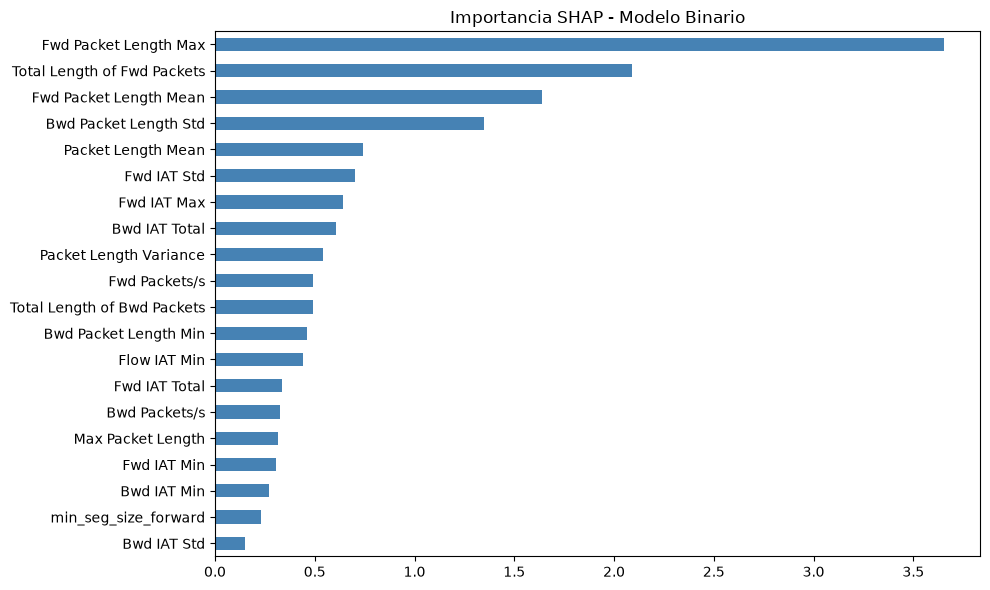

In [8]:
X_amostra, _ = stratified_sample(X_test, y_test, 5000)
shap_final = shap_importance(modelo, X_amostra)

plt.figure(figsize=(10, 6))
shap_final[::-1].plot.barh(color='steelblue')
plt.title('Importancia SHAP - Modelo Binario')
plt.tight_layout()
plt.show()

## 6. Salvar modelo

In [9]:
report = classification_report(y_test, pred_test, output_dict=True)
metadata = {
    'features': features,
    'threshold': threshold,
    'classes': ['BENIGN', 'Ataque'],
    'xgb_params': {**XGB_PARAMS, **PARAMS},
    'metricas_teste': {
        'recall_ataque': round(report['1']['recall'], 6),
        'precisao_ataque': round(report['1']['precision'], 6),
        'f1_ataque': round(report['1']['f1-score'], 6),
        'falsos_positivos': int(cm[0, 1]),
        'falsos_negativos': int(cm[1, 0]),
        'recall_por_tipo': recall_tipo['recall'].round(6).to_dict(),
    },
}
save_model(modelo, 'modelo_binario', metadata)
print(json.dumps(metadata['metricas_teste'], indent=2))

{
  "recall_ataque": 0.999356,
  "precisao_ataque": 0.998864,
  "f1_ataque": 0.99911,
  "falsos_positivos": 30,
  "falsos_negativos": 17,
  "recall_por_tipo": {
    "DDoS": 0.99957,
    "PortScan": 0.994792,
    "SQLInjection": 0.333333,
    "WebAttack": 0.994987
  }
}
